# 52 · MDP와 Bellman: 작은 환경의 정확한 가치를 구하기

📎 **이번 질문** · 과일을 배달할 때 바로 우회로를 택할지, 확률적으로 통과하는 다리를 택할지 어떻게 비교할까요? 오늘 받은 보상뿐 아니라 그 선택이 남긴 다음 상태의 가치도 필요합니다.

네 상태·두 행동의 전이표를 직접 만듭니다. 정책의 가치를 선형 방정식으로 풀고, 같은 답을 Bellman 반복·정책 반복·독립 rollout으로 확인합니다. 이번에는 환경 표를 알고 계획합니다. 다음 단원에서는 표를 모른 채 받은 경험으로 값을 배우게 됩니다.

- 준비물: [11 행렬과 선형 방정식](../02_연결/11_linear_algebra.ipynb), [51 bandit](51_bandits.ipynb). 표본 오차는 [27 Monte Carlo](../04_생성/27_monte_carlo_gradients.ipynb)를 다시 사용합니다.
- NumPy·CPU만 사용하며 외부 데이터가 필요하지 않습니다.

### 읽는 법

| 표시 | 뜻 | 읽는 방법 |
|---|---|---|
| 🔑 핵심 | 식·구현 | 상태·행동·다음 상태 축을 적습니다 |
| 🔍 확인 | 그림·검산 | 정확해와 반복 근사·표본 오차를 구분합니다 |
| 📎 참고 | 용어·코드 | 필요한 자리에서 확인합니다 |
| ✏️ 연습 | 한두 줄 구현 | 손계산 뒤 검사합니다 |

**이 노트북에서 반드시 가져갈 세 가지**

1. 전이는 `(현재 상태,행동,다음 상태)`의 세 축입니다. 다음 상태를 합한 뒤 정책으로 행동을 평균합니다.
2. 정책 평가와 최적 제어는 각각 행동 평균과 행동 최댓값을 사용합니다. 정확한 선형해와 정책 8개 전수열거가 검산 기준입니다.
3. 환경의 진짜 종료와 외부 수집 제한은 다릅니다. 수집한 보상만의 유한 목적과 남은 가치를 붙인 목적을 따로 비교합니다.

| 기호 | shape | 의미 |
|---|---|---|
| P,R | `(S,A,S)` | 전이 확률·그 전이에서 받는 보상 |
| π,Q | `(S,A)` | 상태별 행동 확률·행동 가치 |
| V,terminal | `(S,)` | 상태 가치·환경 종료 표시 |
| return 표본 | `(M,)` | 같은 시작 상태에서 독립 실행 M개의 결과 |

[전체 경로](../../docs/CURRICULUM.md) · [그림 보조 코드](../../src/utils/mdp_plots.py)

In [1]:
# 준비 셀: 공통 부품을 불러옵니다.
import sys
from pathlib import Path
import numpy as np
project_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/utils/plotting.py').is_file())
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
from src.utils import setup_plots, run_check
from src.utils.mdp_plots import (
    plot_mdp_transition, plot_return_path, plot_bellman_backup, plot_policy_solution,
    plot_policy_improvement, plot_value_iterations, plot_rollout_boundary, plot_rollout_comparison,
)
setup_plots()
print('상태0 시작 · 상태1 다리 · 상태2 우회 · 상태3 종료')

상태0 시작 · 상태1 다리 · 상태2 우회 · 상태3 종료


## 🔑 1. 전이와 보상을 같은 세 축에 적습니다

**이 절에서 가져갈 것:** 전이 확률은 다음 상태 축에서 합이 1이고, 보상은 선택한 전이에 붙습니다.

배달 시작 0에서 행동 0은 80%로 다리 1, 20%로 우회 2로 갑니다. 행동 1은 즉시 보상 0.2를 받고 우회 2로 확실히 갑니다. 상태 3은 배달 종료입니다.

> **용어**
>
> - **상태(state)**는 미래를 예측하는 데 필요한 현재 상황입니다. 여기서는 장소 번호 0–3입니다.
> - **MDP(Markov decision process)**는 현재 상태와 행동이 다음 상태·보상의 조건부 분포를 결정하는 환경입니다. 이 조건 아래 더 오래된 경로를 전이표에 다시 넣지 않습니다.
> - **terminal 상태**는 환경 자체가 끝나는 상태입니다. 그 뒤에는 새로운 보상이 없습니다.

$$P_{sas'}=P(S_{t+1}=s'\mid S_t=s,A_t=a),\qquad
\sum_{s'}P_{sas'}=1,\qquad r(s,a)=\sum_{s'}P_{sas'}R_{sas'}.$$

이번 보상은 전이가 정해지면 정해지는 숫자입니다. `R[s,a,s_next]`가 그 전이의 보상이며, 보상이 한 번 나온 뒤 다음 상태가 terminal이면 끝납니다.

| 현재 상태 | 행동0의 결과 `(다음 상태,확률,보상)` | 행동1의 결과 |
|---|---|---|
| 0 시작 | (1,.8,0), (2,.2,0) | (2,1,.2) |
| 1 다리 | (1,.5,−.1), (3,.5,1) | (3,1,.6) |
| 2 우회 | (0,.5,−.1), (3,.5,.8) | (3,1,.4) |
| 3 종료 | (3,1,0) | (3,1,0) |

종료 행도 합이 1이도록 자기 자신으로 보내되, 계산에서는 종료 **뒤** 가치를 0으로 막습니다. 종료로 들어갈 때의 마지막 보상까지 지우지는 않습니다.

In [2]:
start_transition = np.array([[0.0,0.8,0.2,0.0],[0.0,0.0,1.0,0.0]])
start_rewards = np.array([[0.0,0.0,0.0,0.0],[0.0,0.0,0.2,0.0]])
start_expected_reward = (start_transition * start_rewards).sum(axis=1)
start_expected_loop = np.zeros(2)
for action in range(2):
    for next_state in range(4):
        start_expected_loop[action] += start_transition[action,next_state] * start_rewards[action,next_state]

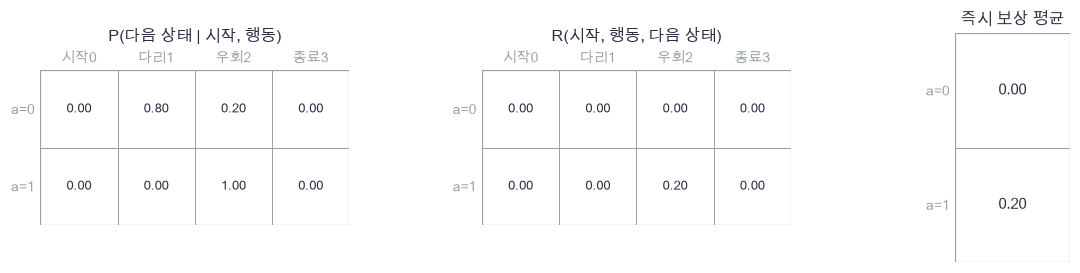

In [3]:
plot_mdp_transition(start_transition, start_rewards, start_expected_reward)

🔍 **확인** · 오른쪽 즉시 평균 보상은 (0,0.2)입니다. 이것만으로 모든 미래를 포함한 최적 행동을 결정하지 않습니다. 아래에서 환경 전체를 같은 규칙으로 만듭니다.

> **코드** · `P[0,0,[1,2]]=[.8,.2]`는 두 다음 상태 칸에 값을 나누어 넣습니다. `np.zeros((4,2,4))`의 마지막 축이 다음 상태입니다. `sum(axis=2)`는 그 축만 줄입니다.

In [4]:
def make_mdp():
    """네 상태·두 행동의 전이 P와 전이별 보상 R:(S,A,S), terminal:(S,)을 만듭니다."""
    P = np.zeros((4,2,4))
    R = np.zeros_like(P)
    P[0,0,[1,2]] = [0.8,0.2]
    P[0,1,2] = 1.0
    R[0,1,2] = 0.2
    P[1,0,[1,3]] = [0.5,0.5]
    R[1,0,[1,3]] = [-0.1,1.0]
    P[1,1,3] = 1.0
    R[1,1,3] = 0.6
    P[2,0,[0,3]] = [0.5,0.5]
    R[2,0,[0,3]] = [-0.1,0.8]
    P[2,1,3] = 1.0
    R[2,1,3] = 0.4
    P[3,:,3] = 1.0
    terminal = np.array([False,False,False,True])
    return P,R,terminal

In [5]:
P,R,terminal = make_mdp()
np.testing.assert_allclose(P.sum(axis=2),1.0)  # 검산: 모든 상태·행동의 다음 상태 확률 합=1
np.testing.assert_allclose(P[0],start_transition)  # 검산: 전체 환경의 시작 전이=손계산 표
np.testing.assert_allclose((P[0]*R[0]).sum(axis=1),start_expected_loop)  # 검산: 벡터화 즉시 보상=반복문
np.testing.assert_allclose(R[3],0.0)  # 검산: 종료 뒤 보상=0
assert np.all(P>=0), '모든 전이 확률은 비음수이어야 합니다'
print('전이의 세 축·행 합·즉시 보상·종료 규약 통과')

전이의 세 축·행 합·즉시 보상·종료 규약 통과


### ✏️ 연습 1 · 다음 상태에 대한 보상 평균

연습은 코딩 테스트처럼 **함수 뼈대가 미리 있고 핵심 한두 줄만 비어 있습니다.** `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓴 뒤, 셀을 실행하고 바로 아래 검사 셀을 실행하세요. 아직 채우지 않았으면 안내문만 나오고, 값이 다르면 "손계산과 다릅니다"가 나옵니다. 막히면 그 아래 "정답 보기"를 펼칩니다.

P와 R이 `(S,A,S)`일 때 즉시 평균 보상을 `(S,A)`로 구하세요.

In [6]:
def exercise_reward(transition, reward):
    """다음 상태에 대한 보상 평균의 핵심 식을 완성합니다."""
    raise NotImplementedError
    return average

In [7]:
def check_reward(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    p=np.array([[[0.25,0.75]]])
    r=np.array([[[2.0,-2.0]]])
    np.testing.assert_allclose(fn(p,r),[[-1.0]])  # 검산: .25×2+.75×(-2)=-1
    print('다음 상태 축 기대값 통과')

run_check(check_reward,exercise_reward,hint='행동 축은 남기고 마지막 축만 합합니다.')

☐ exercise_reward: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 행동 축은 남기고 마지막 축만 합합니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
average = (transition * reward).sum(axis=2)
```

</details>

## 🔑 2. 보상을 할인해 더하고 마지막 경계를 표시합니다

**이 절에서 가져갈 것:** return의 시간 지수는 0부터 시작하며, 진짜 종료에서만 미래 값을 0으로 만듭니다.

배달에서 지금 얻은 보상과 여러 전이 뒤 얻을 보상을 구분하고 싶습니다. 고정 할인율 γ=0.9를 사용합니다.

> **용어**
>
> - **return G**는 한 경로에서 받은 미래 보상을 할인해 더한 값입니다.
> - **할인율(discount) γ**는 한 단계 뒤의 보상에 곱하는 계수입니다. 여기서는 0≤γ<1입니다.
> - **truncation**은 환경이 끝나지 않았지만 수집 예산 H 때문에 관측을 멈춘 것입니다.
> - **bootstrap**은 남은 미래 보상을 현재의 가치 추정으로 이어 붙이는 것입니다. 정확한 V를 쓰는 이번 검산과 추정 V를 쓰는 다음 단원을 구분합니다.

$$G_{0:H}=\sum_{t=0}^{H-1}\gamma^tR_{t+1},\qquad
G_{0:H}^{boot}=G_{0:H}+\gamma^H\mathbf1[\text{진짜 종료 아님}]V(S_H).$$

첫 보상에는 γ⁰=1이 붙습니다. 보상 [1,0.5]의 유한 합은 1.45입니다. 진짜 종료라면 그대로이고, 단순 수집 제한이며 마지막 V를 2로 정했다면 1.45+0.9²×2=3.07입니다. **시간 제한이 원래 과제의 종료 규칙이면** 남은 시간을 상태에 포함한 유한-horizon MDP로 정의해야 합니다. 여기의 H는 과제 밖 수집 제한입니다.

> **코드** · `gamma ** np.arange(len(rewards))`는 `[1,γ,γ²,…]`입니다. `reversed(rewards)`로 마지막부터 `G←r+γG`를 계산해도 같은 합입니다.

In [8]:
gamma = 0.9
return_rewards = np.array([1.0,0.5])
return_powers = gamma ** np.arange(len(return_rewards))
return_contributions = return_powers * return_rewards
finite_hand = return_contributions.sum()
bootstrap_hand = finite_hand + gamma**2 * 2.0
return_totals = np.array([finite_hand,bootstrap_hand])

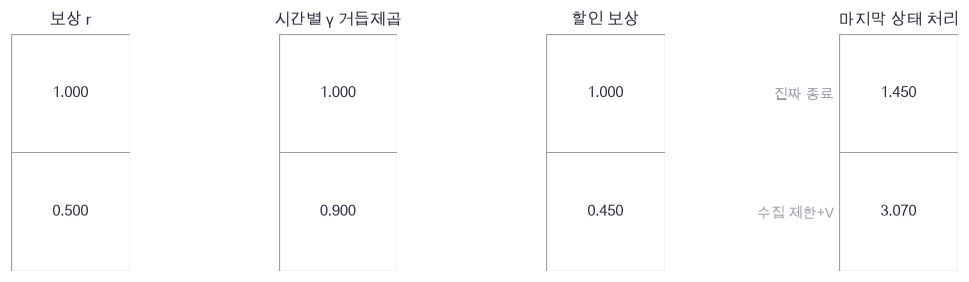

In [9]:
plot_return_path(return_rewards, return_powers, return_contributions, return_totals)

🔍 **확인** · 두 값의 차이는 관측 보상이 아니라 관측하지 않은 미래입니다. 마지막 관측 이후의 상태가 terminal인지 따로 보관해야 두 경우를 구분할 수 있습니다. 이 손계산의 보상·V=2는 경계 계산을 설명하는 독립 숫자 예입니다.

In [10]:
def discounted_return(rewards, gamma, final_value=0.0, terminated=True):
    """관측 보상열을 역순으로 합합니다. 진짜 종료이면 final_value를 무시합니다."""
    value = 0.0 if terminated else float(final_value)
    for reward in reversed(rewards):
        value = float(reward) + gamma * value
    return value

In [11]:
np.testing.assert_allclose(discounted_return(return_rewards,gamma,99.0,True),1.45)  # 검산: terminal이면 임의의 큰 마지막 값도 무시
np.testing.assert_allclose(discounted_return(return_rewards,gamma,2.0,False),3.07)  # 검산: 단순 수집 제한에서는 γ²V를 더함
np.testing.assert_allclose(discounted_return([2.0,100.0],0.0),2.0)  # 검산: γ0이면 첫 보상만 남음
np.testing.assert_allclose(discounted_return([],gamma,2.0,False),2.0)  # 검산: 전이를 아직 수집하지 않으면 남은 가치만
print('시간 지수·역순 합·terminal/truncation 경계 통과')

시간 지수·역순 합·terminal/truncation 경계 통과


### ✏️ 연습 2 · 정확한 종료 마스크

한 보상과 다음 상태 가치를 받아 bootstrap 타깃 한 개를 만드세요.

In [12]:
def exercise_boundary(reward, next_value, gamma, terminated):
    """정확한 종료 마스크의 핵심 식을 완성합니다."""
    raise NotImplementedError
    return target

In [13]:
def check_boundary(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    np.testing.assert_allclose(fn(1.,9.,.9,True),1.)  # 검산: 진짜 종료는 마지막 보상만
    np.testing.assert_allclose(fn(1.,2.,.9,False),2.8)  # 검산: 비종료는1+.9×2
    print('종료 뒤 가치만 제거 통과')

run_check(check_boundary,exercise_boundary,hint='보상 자체에는 terminal 마스크를 곱하지 않습니다.')

☐ exercise_boundary: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 보상 자체에는 terminal 마스크를 곱하지 않습니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
target = reward + gamma * (1.0 - float(terminated)) * next_value
```

</details>

## 🔑 3. 정책의 가치를 Bellman 방정식으로 풉니다

**이 절에서 가져갈 것:** 다음 상태 합과 정책의 행동 평균을 분리하면 가치의 선형 방정식이 됩니다.

각 장소에서 두 행동을 반씩 고르는 정책 π를 먼저 평가합니다. 지금의 한 보상 뒤에는 같은 정책을 계속 따른다고 약속합니다.

$$Q^\pi(s,a)=\sum_{s'}P_{sas'}[R_{sas'}+\gamma m_{s'}V^\pi(s')],\qquad
V^\pi(s)=\sum_a\pi(a\mid s)Q^\pi(s,a),\quad m_{s'}=1-\mathbf1[terminal(s')].$$

Q는 `(S,A)`이고 V는 `(S,)`입니다. $\widetilde P^\pi_{ss'}=\sum_a\pi_{sa}P_{sas'}m_{s'}$, $r^\pi_s=\sum_{a,s'}\pi_{sa}P_{sas'}R_{sas'}$를 쓰면

$$(I-\gamma\widetilde P^\pi)V^\pi=r^\pi.$$

행에 현재 상태, 열에 다음 상태를 둡니다. 종료 열을 제거한 전이의 행 합은 1 이하입니다. γ<1이라 선형 시스템을 풀 수 있고, 같은 Bellman 갱신을 반복해도 답에 접근합니다. 모든 상태를 이전 V 하나로 동시에 갱신합니다.

> **용어** · **Bellman 기대 방정식**은 지금의 보상과 다음 상태의 가치로 현재 가치를 다시 쓰는 식입니다. **정책 평가**는 π를 고정한 채 V를 계산하는 것입니다. 신경망 학습이나 정책 변경과 다릅니다.
>
> **코드** · `continuation[None,None,:]`는 `(1,1,S)`로 축을 추가해 모든 현재 상태·행동에서 같은 다음 가치 배열을 씁니다. `policy[:,:,None]`은 `(S,A,1)`입니다.

> **코드** · `np.linalg.solve(A,b)`는 역행렬을 직접 만들지 않고 `A @ x = b`를 만족하는 x를 풉니다. 그림의 역행렬 표기와 같은 해입니다.

In [14]:
# 쓰는 것: P, R, gamma, terminal (위 절의 정의·실행 셀)
policy = np.full((4,2),0.5)
backup_values = np.array([0.2,0.4,0.6,99.0])
backup_continuation = backup_values * (1.0-terminal.astype(float))
backup_contributions = P[0] * (R[0] + gamma*backup_continuation)
backup_q = backup_contributions.sum(axis=1)
backup_v = np.sum(policy[0]*backup_q)
print('시작 Q:',backup_q,'· 새 V:',backup_v)

시작 Q: [0.396 0.74 ] · 새 V: 0.5680000000000001


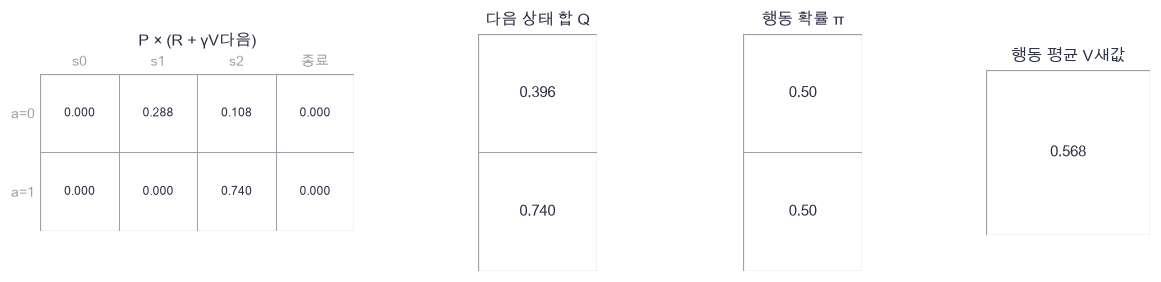

In [15]:
plot_bellman_backup(backup_contributions, backup_q, policy[0], backup_v)

🔍 **확인** · 종료 상태에 일부러 99를 넣어도 미래 기여는 0입니다. 시작 상태의 두 Q는 0.396과 0.74이고, 정책 평균은 0.568입니다. 다음 상태 합과 행동 평균을 같은 축에서 계산하지 않습니다.

In [16]:
def action_values(P,R,terminal,values,gamma):
    """q(s,a)=Σs' P[R+γ(1−terminal')V']. (S,A,S) → (S,A)."""
    continuation = values * (1.0-terminal.astype(float))
    return np.sum(P * (R + gamma * continuation[None,None,:]), axis=2)

In [17]:
def policy_backup(P,R,terminal,policy,values,gamma):
    """정책 π:(S,A)로 행동 가치를 평균해 Bellman 갱신 한 번. → V새값:(S,)."""
    return np.sum(policy * action_values(P,R,terminal,values,gamma), axis=1)

In [18]:
def policy_value_exact(P,R,terminal,policy,gamma):
    """종료 뒤 전이를 제외한 (I−γPπ)V=rπ를 풉니다. → 정확한 수치 선형해:(S,)."""
    transition = np.sum(policy[:,:,None] * P, axis=1)
    continuation = transition * (1.0-terminal.astype(float))[None,:]
    reward = np.sum(policy * np.sum(P*R, axis=2), axis=1)
    return np.linalg.solve(np.eye(len(terminal))-gamma*continuation,reward)

In [19]:
def evaluate_policy_iterative(P,R,terminal,policy,gamma,tolerance=1e-10):
    """V=0에서 동시 Bellman 갱신을 반복합니다. 최종 V와 모든 반복의 V 표를 반환합니다."""
    values = np.zeros(len(terminal))
    history = [values.copy()]
    for step in range(10000):
        updated = policy_backup(P,R,terminal,policy,values,gamma)
        history.append(updated.copy())
        change = np.max(np.abs(updated-values))
        values = updated
        if change < tolerance:
            return values,np.array(history)
    raise RuntimeError('지정 반복 수 안에 수렴하지 않았습니다')

In [20]:
# 쓰는 것: P, R, action_values, backup_values, gamma, policy, terminal (위 절의 정의·실행 셀)
np.testing.assert_allclose(action_values(P,R,terminal,backup_values,gamma)[0],[0.396,0.74])  # 검산: 전이 네 칸의 직접 손계산
np.testing.assert_allclose(policy_backup(P,R,terminal,policy,backup_values,gamma)[0],0.568)  # 검산: 두 행동의 반반 평균
exact_policy_value = policy_value_exact(P,R,terminal,policy,gamma)
iterative_value,policy_evaluation_history = evaluate_policy_iterative(P,R,terminal,policy,gamma)
np.testing.assert_allclose(policy_backup(P,R,terminal,policy,exact_policy_value,gamma),exact_policy_value,atol=1e-12)  # 검산: 선형해의 Bellman 잔차=0
np.testing.assert_allclose(iterative_value,exact_policy_value,atol=1e-9)  # 검산: 실제 동시 반복과 선형 시스템 독립 계산 일치
np.testing.assert_allclose(exact_policy_value[3],0.0)  # 검산: 종료 상태의 가치=0
print('정책 가치 정확해:',np.round(exact_policy_value,6),'· 반복 수:',len(policy_evaluation_history)-1)

정책 가치 정확해: [0.621936 0.677419 0.514936 0.      ] · 반복 수: 23


In [21]:
# 쓰는 것: P, R, policy, terminal (위 절의 정의·실행 셀)
policy_transition = np.sum(policy[:,:,None]*P,axis=1) * (1.0-terminal)[None,:]
policy_immediate = np.sum(policy * np.sum(P*R,axis=2),axis=1)

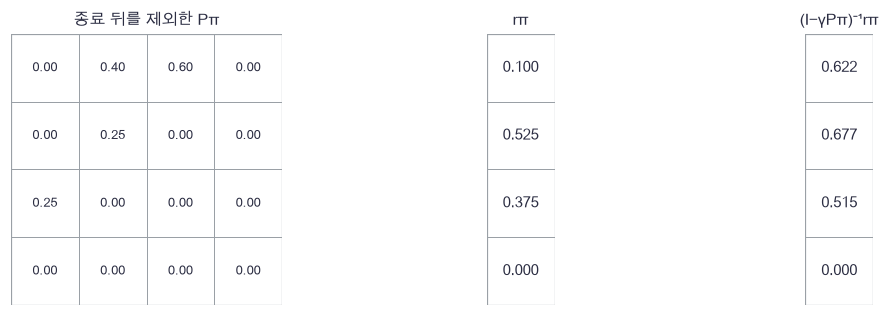

In [22]:
plot_policy_solution(policy_transition, policy_immediate, exact_policy_value)

🔍 **확인** · 종료로 가는 확률이 전이 표에서 빠져도, 종료로 들어가며 받는 보상은 rπ에 남습니다. 구현은 역행렬을 직접 만들지 않고 `np.linalg.solve`로 선형 시스템을 풉니다. 위 그림의 역행렬 표기는 그 방정식의 해를 나타냅니다.

### ✏️ 연습 3 · 행동 평균으로 정책 가치를 갱신합니다

policy와 q의 shape는 `(S,A)`입니다.

In [23]:
def exercise_policy_backup(policy, q):
    """행동 평균으로 정책 가치를 갱신합니다의 핵심 식을 완성합니다."""
    raise NotImplementedError
    return values

In [24]:
def check_policy_backup(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    pi=np.array([[.25,.75],[1.,0.]])
    q=np.array([[2.,4.],[3.,9.]])
    np.testing.assert_allclose(fn(pi,q),[3.5,3.])  # 검산: .25×2+.75×4와 행동0만의3
    print('정책의 행동 평균 통과')

run_check(check_policy_backup,exercise_policy_backup,hint='다음 상태 합은 q 안에서 이미 끝났습니다.')

☐ exercise_policy_backup: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 다음 상태 합은 q 안에서 이미 끝났습니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
values = (policy * q).sum(axis=1)
```

</details>

## 🔑 4. 행동 평균을 최댓값으로 바꾸어 계획합니다

**이 절에서 가져갈 것:** value iteration과 policy iteration을 실제로 반복하고, 가능한 정책 전체의 정확한 가치로 대조합니다.

반반 정책보다 좋은 배달 선택을 찾겠습니다. 현재 Vπ로 각 행동의 Q를 비교하면 더 큰 Q의 행동으로 정책을 개선할 수 있습니다.

$$T_\star V(s)=\max_a\sum_{s'}P_{sas'}[R_{sas'}+\gamma m_{s'}V(s')].$$

**value iteration**은 $V_{k+1}=T_\star V_k$를 반복합니다. **policy iteration**은 현재 정책의 정확한 평가→greedy 개선을 반복합니다. 이번 deterministic 정책의 동률은 작은 행동 번호로 고정하며, 종료 상태의 행동은 가치에 영향을 주지 않습니다.

> **용어** · **동적 계획법(dynamic programming)**은 알고 있는 전이·보상 표와 부분 문제의 가치를 이용해 계획하는 방법입니다. **최적 가치 V★**는 가능한 정책 가운데 가장 큰 기대 return입니다. 이 단원의 정확한 표 기반 계획과 이후 표본 학습을 구별합니다.

γ<1일 때 Bellman 최적 연산은 sup norm에서 γ-수축입니다. 임의의 V에 대해 잔차 $\delta=\|T_\star V-V\|_\infty$를 계산하면

$$\|V-V^\star\|_\infty\le\frac{\delta}{1-\gamma}.$$

이 부등식은 알려진 모델의 수치 반복 오차에 대한 것입니다. 환경 모델이 틀리거나 rollout 표본이 흔들리는 오차까지 포함하지 않습니다.

> **코드** · `argmax(axis=1)`은 각 상태에서 최대 행동 번호를 줍니다. `np.eye(A)[actions]`는 그 행동만 확률1인 정책입니다. `copy()`는 다음 반복에서 기록이 바뀌지 않게 배열을 복사합니다.

In [25]:
# 쓰는 것: P, R, action_values, exact_policy_value, gamma, terminal (위 절의 정의·실행 셀)
improvement_q = action_values(P,R,terminal,exact_policy_value,gamma)
improvement_actions = improvement_q.argmax(axis=1)
improvement_policy = np.eye(2)[improvement_actions]

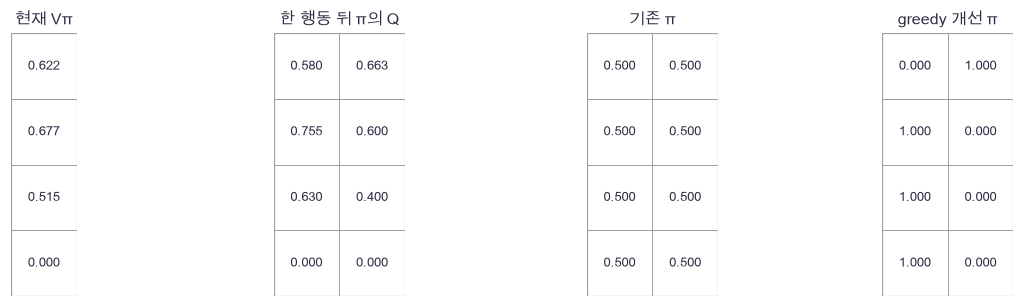

In [26]:
plot_policy_improvement(exact_policy_value, improvement_q, policy, improvement_policy)

🔍 **확인** · 이 그림은 현재 반반 정책을 평가한 뒤 한 번 개선한 실제 단계입니다. 종료 행의 행동은 모두 가치0입니다. 어느 행동이 최적인지는 다음의 반복과 전수열거로 확인합니다.

In [27]:
def value_iteration(P,R,terminal,gamma,tolerance=1e-10):
    """최대 행동 Bellman 연산으로 실제 V를 반복 갱신하고 greedy 정책을 반환합니다."""
    # 쓰는 것: action_values (위 절의 정의·실행 셀)
    values = np.zeros(len(terminal))
    history = [values.copy()]
    for step in range(10000):
        updated = action_values(P,R,terminal,values,gamma).max(axis=1)
        history.append(updated.copy())
        change = np.max(np.abs(updated-values))
        values = updated
        if change < tolerance:
            greedy = action_values(P,R,terminal,values,gamma).argmax(axis=1)
            policy = np.eye(P.shape[1])[greedy]
            return values,policy,np.array(history)
    raise RuntimeError('지정 반복 수 안에 수렴하지 않았습니다')

In [28]:
def policy_iteration(P,R,terminal,gamma):
    """정확한 정책 평가와 greedy 개선을 반복합니다. 동률은 작은 행동 번호로 고정합니다."""
    # 쓰는 것: action_values, policy_value_exact (위 절의 정의·실행 셀)
    actions = np.zeros(len(terminal),dtype=int)
    records = []
    for step in range(100):
        policy = np.eye(P.shape[1])[actions]
        values = policy_value_exact(P,R,terminal,policy,gamma)
        records.append(values.copy())
        improved = action_values(P,R,terminal,values,gamma).argmax(axis=1)
        if np.array_equal(improved,actions):
            return values,policy,np.array(records)
        actions = improved
    raise RuntimeError('정책 반복이 제한 안에 끝나지 않았습니다')

In [29]:
# 쓰는 것: P, R, gamma, policy_value_exact, terminal (위 절의 정의·실행 셀)
optimal_values,optimal_policy,value_history = value_iteration(P,R,terminal,gamma)
pi_values,pi_policy,pi_history = policy_iteration(P,R,terminal,gamma)
np.testing.assert_allclose(optimal_values,pi_values,atol=1e-9)  # 검산: 서로 다른 두 동적 계획 반복의 가치 일치
exact_greedy_value = policy_value_exact(P,R,terminal,optimal_policy,gamma)
np.testing.assert_allclose(optimal_values,exact_greedy_value,atol=1e-9)  # 검산: 마지막 greedy 정책의 정확한 평가
print('최적 가치:',np.round(optimal_values,6),'· 선택 행동:',optimal_policy.argmax(axis=1))
print('value iteration 갱신:',len(value_history)-1,'· policy evaluation 횟수:',len(pi_history))

최적 가치: [0.865546 0.818182 0.739496 0.      ] · 선택 행동: [1 0 0 0]
value iteration 갱신: 51 · policy evaluation 횟수: 2


📎 **정책을 전부 나열하는 독립 검산** · 비종료 상태 3개마다 행동 2개이므로 deterministic 정책은 2³=8개입니다. 각 정책을 선형 방정식으로 풀고 상태별 최대를 취해 두 반복 결과를 대조합니다. 표본 성공률을 assert하는 대신 유한한 정책 공간의 정확한 항등식을 검사합니다.

> **코드** · `(number // (2**state)) % 2`는 정책 번호의 이진 자리 하나를 읽습니다. `np.stack`은 정책별 `(S,)` 가치를 `(8,S)`로 쌓습니다.

In [30]:
# 쓰는 것: P, R, action_values, gamma, policy_value_exact, terminal (위 절의 정의·실행 셀)
enumerated_values = []
for number in range(8):
    actions = np.zeros(4,dtype=int)
    for state in range(3):
        actions[state] = (number // (2**state)) % 2
    candidate_policy = np.eye(2)[actions]
    enumerated_values.append(policy_value_exact(P,R,terminal,candidate_policy,gamma))
enumerated_values = np.stack(enumerated_values)
enumerated_optimum = enumerated_values.max(axis=0)
np.testing.assert_allclose(optimal_values,enumerated_optimum,atol=1e-9)  # 검산: Bellman 최적해 = 8개 정책 전수열거
optimal_residual = np.max(np.abs(action_values(P,R,terminal,optimal_values,gamma).max(axis=1)-optimal_values))
actual_error = np.max(np.abs(optimal_values-enumerated_optimum))
assert actual_error <= optimal_residual/(1-gamma)+1e-12, '수치 반올림 여유 안에서 잔차 오차 상한을 만족해야 합니다'
print('정책 8개 전수열거 통과 · 잔차:',optimal_residual,'· 정확해 오차:',actual_error)

정책 8개 전수열거 통과 · 잔차: 5.468736574698596e-11 · 정확해 오차: 1.0161749219861349e-10


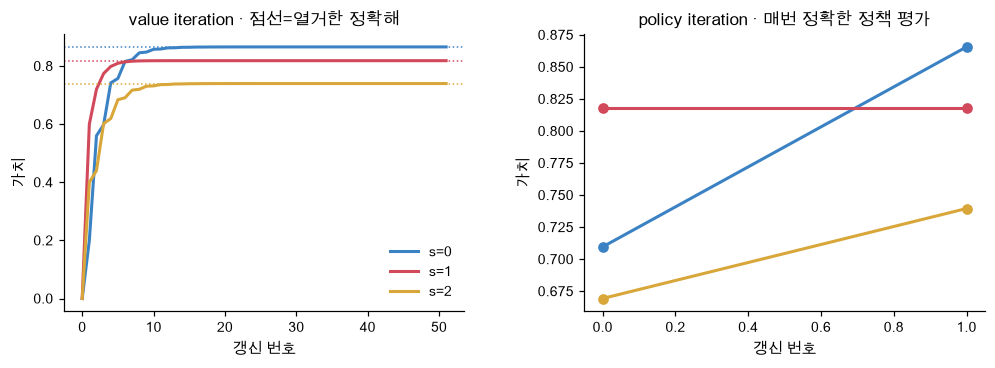

In [31]:
plot_value_iterations(value_history, enumerated_optimum, pi_history)

🔍 **확인** · 실제 반복에서 저장한 값이 열거한 정확해로 접근합니다. policy iteration의 평가 한 번은 선형 시스템을 푸는 계산이므로, 단순 반복 횟수만으로 두 방법의 연산 비용이 같다고 비교하지 않습니다.

### ✏️ 연습 4 · 최댓값으로 행동을 개선합니다

Q:(S,A)를 받아 deterministic greedy 정책을 만드세요.

In [32]:
def exercise_greedy(q):
    """최댓값으로 행동을 개선합니다의 핵심 식을 완성합니다."""
    raise NotImplementedError
    return policy

In [33]:
def check_greedy(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    np.testing.assert_allclose(fn(np.array([[1.,2.],[3.,3.]])),[[0.,1.],[1.,0.]])  # 검산: 첫 상태행동1, 동률은작은번호0
    print('정책 개선과 동률 규약 통과')

run_check(check_greedy,exercise_greedy,hint='51의 동률 균등 정책과 이번 deterministic 규약의 차이를 기억하세요.')

☐ exercise_greedy: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 51의 동률 균등 정책과 이번 deterministic 규약의 차이를 기억하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
policy = np.eye(q.shape[1])[q.argmax(axis=1)]
```

</details>

## 🔑 5. rollout을 정확한 유한·무한 목적과 비교합니다

**이 절에서 가져갈 것:** 수집 horizon을 바꿀 때 비교할 정확한 목적도 구분하고, 독립 episode의 평균·SE를 보고합니다.

계산한 V가 실제 경로들의 평균과 연결되는지 확인하겠습니다. 여기서는 최적 정책 대신 앞서 고정한 **반반 정책**을 사용합니다. 시작 상태는 0이고 H=2·5·30에서 각각 독립 episode 4,000개를 수집합니다.

보상만 더한 유한 목적의 정확한 값은 $V_0=0$, $V_{h+1}=T_\pi V_h$를 H번 적용한 $V_H$입니다. 무한 목적은 3절의 선형해 Vπ입니다. 정확한 Vπ를 마지막 비종료 상태에 붙이면 반복 기대값은 같은 무한 목적이 됩니다.

$$\mathbb E[G_{0:H}]=V_H(0),\qquad
\mathbb E[G_{0:H}+\gamma^H m_{S_H}V^\pi(S_H)]=V^\pi(0).$$

중간에 종료했다면 마지막 항은 0이고 H 이전에 끝나도 같습니다. 남은 가치가 추정 오차를 가지면 이 두 번째 등식은 일반적으로 정확하지 않습니다. 아래는 **정확한 V를 쓰는 통제 검산**입니다.

> **용어** · **rollout**은 정책에 따라 환경의 상태·보상을 실제로 뽑아 만든 경로입니다. **episode** 하나가 독립 평가 단위입니다. 한 경로 안의 연속 상태들을 독립 표본으로 세지 않습니다.
>
> **코드** · `rng.choice(A,p=policy[state])`는 그 상태의 행동 확률로 행동 하나를 뽑습니다. 다음 상태도 P의 해당 행으로 뽑습니다. `std(ddof=1)/sqrt(M)`은 M개 독립 episode 평균의 SE입니다.

In [34]:
# 쓰는 것: exact_policy_value, gamma, terminal (위 절의 정의·실행 셀)
boundary_states = np.array([0,1,1])
boundary_rewards = np.array([0.0,-0.1])
boundary_terminal = terminal[boundary_states[-1]]
boundary_bootstrap = gamma**len(boundary_rewards) * exact_policy_value[boundary_states[-1]]

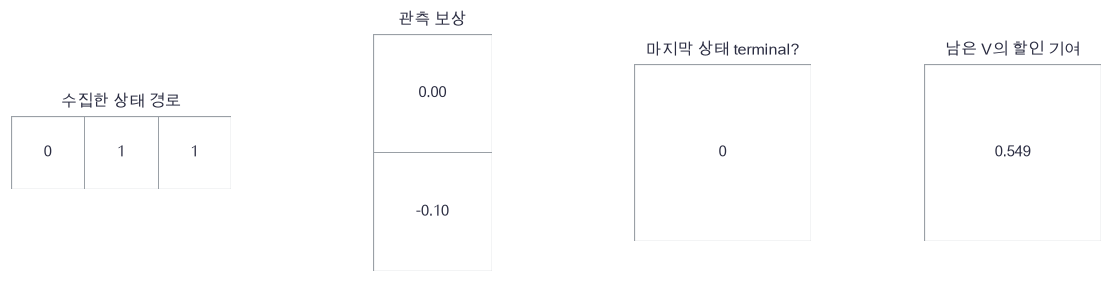

In [35]:
plot_rollout_boundary(boundary_states, boundary_rewards, boundary_terminal, boundary_bootstrap)

🔍 **확인** · 0→1→1은 환경 표에서 가능한 경로입니다. 두 번 관측했어도 마지막 상태1은 종료가 아니므로 남은 가치가 있습니다. 아래의 rollout 함수는 보상을 실제로 뽑고, `terminated`와 수집 횟수를 별도로 관리합니다.

In [36]:
def rollout_returns(P,R,terminal,policy,gamma,start,horizon,episodes,seed,bootstrap_values):
    """독립 episode의 유한 H return와 정확한 V를 붙인 bootstrap return. 환경 종료/수집 제한을 분리합니다."""
    # 쓰는 것: discounted_return (위 절의 정의·실행 셀)
    # 1. 새 난수열과 episode별 기록
    rng = np.random.default_rng(seed)
    finite = np.zeros(episodes)
    bootstrapped = np.zeros(episodes)
    ended = np.zeros(episodes,dtype=bool)
    for episode in range(episodes):
        state = start
        rewards = []
        terminated = bool(terminal[state])
        # 2. 실제 환경 종료가 아니면 최대 horizon개 전이를 수집합니다.
        for step in range(horizon):
            if terminated:
                break
            action = rng.choice(P.shape[1],p=policy[state])
            next_state = rng.choice(len(terminal),p=P[state,action])
            rewards.append(R[state,action,next_state])
            state = next_state
            terminated = bool(terminal[state])
        # 3. terminal은0, 단순 수집 제한은 남은 가치로 이어갑니다.
        finite[episode] = discounted_return(rewards,gamma)
        bootstrapped[episode] = discounted_return(rewards,gamma,bootstrap_values[state],terminated)
        ended[episode] = terminated
    return finite,bootstrapped,ended

In [37]:
# 쓰는 것: P, R, exact_policy_value, gamma, policy, terminal (위 절의 정의·실행 셀)
terminal_finite,terminal_boot,terminal_ended = rollout_returns(P,R,terminal,policy,gamma,3,5,4,5200,exact_policy_value)
np.testing.assert_allclose(terminal_finite,0.0)  # 검산: 종료 상태에서 시작하면 보상 없음
np.testing.assert_allclose(terminal_boot,0.0)  # 검산: 종료 상태에는 bootstrap 없음
assert terminal_ended.all(), '종료 상태에서 시작한 모든 episode는 종료 표시여야 합니다'
zero_finite,zero_boot,zero_ended = rollout_returns(P,R,terminal,policy,gamma,0,0,3,5201,exact_policy_value)
np.testing.assert_allclose(zero_finite,0.0)  # 검산: 수집0회이면 관측 보상0
np.testing.assert_allclose(zero_boot,exact_policy_value[0])  # 검산: 수집0회에서는 시작 가치가 그대로 남음
assert not zero_ended.any(), '수집0회는 환경 종료를 뜻하지 않아야 합니다'
print('rollout의 종료 시작·수집0회 경계 통과')

rollout의 종료 시작·수집0회 경계 통과


In [38]:
# 쓰는 것: P, R, exact_policy_value, gamma, policy, policy_backup, terminal (위 절의 정의·실행 셀)
horizons = [2,5,30]
EPISODES = 4000
finite_means,finite_ses,finite_exact = [],[],[]
bootstrap_means,bootstrap_ses = [],[]
for index,horizon in enumerate(horizons):
    finite,bootstrapped,ended = rollout_returns(P,R,terminal,policy,gamma,0,horizon,EPISODES,5210+index,exact_policy_value)
    exact_horizon = np.zeros(4)
    for step in range(horizon):
        exact_horizon = policy_backup(P,R,terminal,policy,exact_horizon,gamma)
    finite_means.append(finite.mean())
    finite_ses.append(finite.std(ddof=1)/np.sqrt(EPISODES))
    finite_exact.append(exact_horizon[0])
    bootstrap_means.append(bootstrapped.mean())
    bootstrap_ses.append(bootstrapped.std(ddof=1)/np.sqrt(EPISODES))
    print('H',horizon,'종료 비율',round(ended.mean(),3),'· 유한 평균/정확해',round(finite.mean(),4),round(exact_horizon[0],4),'· bootstrap 평균',round(bootstrapped.mean(),4))

H 2 종료 비율 0.753 · 유한 평균/정확해 0.496 0.4915 · bootstrap 평균 0.6248


H 5 종료 비율 0.971 · 유한 평균/정확해 0.6072 0.6121 · bootstrap 평균 0.6175


H 30 종료 비율 1.0 · 유한 평균/정확해 0.6236 0.6219 · bootstrap 평균 0.6236


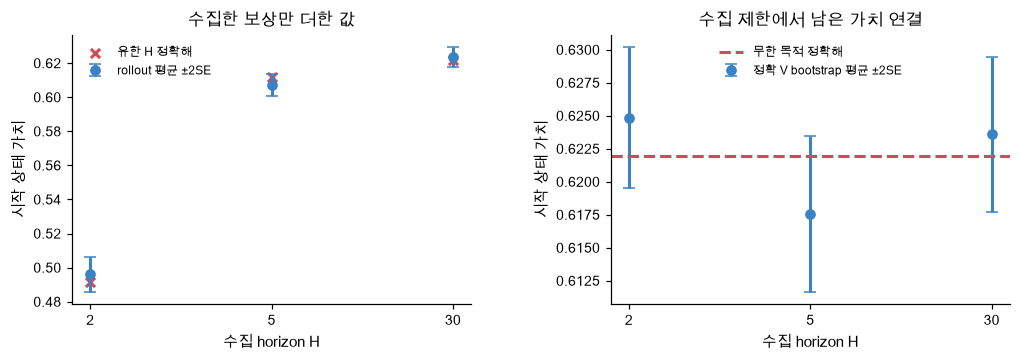

In [39]:
plot_rollout_comparison(horizons, finite_means, finite_ses, finite_exact, bootstrap_means, bootstrap_ses, exact_policy_value[0])

🔍 **확인** · 왼쪽은 H에 따라 목적값 자체가 달라집니다. 오른쪽은 정확한 남은 가치를 붙여 같은 무한 목적을 평가합니다. 오차 막대는 각 H에서 독립 episode 평균의 ±2SE이며, 항상 참값을 포함하는 보장이나 세 H를 한꺼번에 덮는 구간이 아닙니다. 관측 오차를 성공 조건으로 assert하지 않습니다.

이 예의 H=30에서도 유한 보상 합은 정의상 유한 목적입니다. 단지 종료가 빨리 일어나고 할인이 있어 무한 목적에 가까울 수 있습니다. γ=1이나 비종료 순환 환경으로 바꾸면 수렴 조건을 다시 검토해야 합니다.

### ✏️ 연습 5 · 유한 목적을 한 단계 늘립니다

다음 상태의 h단계 가치와 즉시 보상이 주어졌습니다.

In [40]:
def exercise_finite_target(reward, continuation, gamma):
    """유한 목적을 한 단계 늘립니다의 핵심 식을 완성합니다."""
    raise NotImplementedError
    return value

In [41]:
def check_finite_target(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    np.testing.assert_allclose(fn(np.array([0.2,0.0]),np.array([0.4,0.6]),0.5),[0.4,0.3])  # 검산: .2+.5×.4, 0+.5×.6
    print('유한 horizon 한 단계 연결 통과')

run_check(check_finite_target,exercise_finite_target,hint='continuation은 전이·정책 기대값이 이미 계산된 값입니다.')

☐ exercise_finite_target: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: continuation은 전이·정책 기대값이 이미 계산된 값입니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
value = reward + gamma * continuation
```

</details>

## ✏️ 전체 연결 연습 A–D

축·시간·최적 연산·오차 상한을 작은 독립 배열에서 확인합니다.

### ✏️ 연습 A · 정책의 전이 행렬

P:(S,A,S), π:(S,A)에서 행동 축을 평균하세요.

In [42]:
def exercise_transition(transition, policy):
    """정책의 전이 행렬의 핵심 식을 완성합니다."""
    raise NotImplementedError
    return policy_transition

In [43]:
def check_transition(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    p=np.array([[[1.,0.],[0.,1.]],[[.5,.5],[1.,0.]]])
    pi=np.array([[.25,.75],[1.,0.]])
    np.testing.assert_allclose(fn(p,pi),[[.25,.75],[.5,.5]])  # 검산: 각 상태에서 정책으로 행동을 평균
    print('정책 전이 축 통과')

run_check(check_transition,exercise_transition,hint='다음 상태 축은 남깁니다.')

☐ exercise_transition: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 다음 상태 축은 남깁니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
policy_transition = (policy[:,:,None] * transition).sum(axis=1)
```

</details>

### ✏️ 연습 B · 세 보상의 시간 지수

벡터화로 할인 보상 합을 구하세요.

In [44]:
def exercise_powers(rewards, gamma):
    """세 보상의 시간 지수의 핵심 식을 완성합니다."""
    raise NotImplementedError
    return total

In [45]:
def check_powers(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    np.testing.assert_allclose(fn(np.array([1.,2.,4.]),.5),3.)  # 검산: 1+1+1
    print('첫 지수0의 할인 합 통과')

run_check(check_powers,exercise_powers,hint='보상 길이만큼 0부터 지수를 만듭니다.')

☐ exercise_powers: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 보상 길이만큼 0부터 지수를 만듭니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
total = np.sum(rewards * gamma**np.arange(len(rewards)))
```

</details>

### ✏️ 연습 C · 행동 평균 대신 최댓값

Q:(S,A)에서 Bellman 최적 갱신의 마지막 단계를 채우세요.

In [46]:
def exercise_max(q):
    """행동 평균 대신 최댓값의 핵심 식을 완성합니다."""
    raise NotImplementedError
    return value

In [47]:
def check_max(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    np.testing.assert_allclose(fn(np.array([[-1.,-2.],[.3,.8]])),[-1.,.8])  # 검산: 각 상태별 최대
    print('최적 행동 축 통과')

run_check(check_max,exercise_max,hint='전체 배열 최대 한 숫자가 아닙니다.')

☐ exercise_max: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 전체 배열 최대 한 숫자가 아닙니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
value = q.max(axis=1)
```

</details>

### ✏️ 연습 D · 잔차로 반복 오차를 제한합니다

sup norm Bellman 잔차와 0≤γ<1을 받아 오차 상한을 구하세요.

In [48]:
def exercise_bound(residual, gamma):
    """잔차로 반복 오차를 제한합니다의 핵심 식을 완성합니다."""
    raise NotImplementedError
    return bound

In [49]:
def check_bound(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    np.testing.assert_allclose(fn(.02,.9),.2)  # 검산: .02/.1=.2
    print('수축 잔차 상한 통과')

run_check(check_bound,exercise_bound,hint='γ가1에 가까울수록 같은 잔차가 더 큰 가치 오차를 허용합니다.')

☐ exercise_bound: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: γ가1에 가까울수록 같은 잔차가 더 큰 가치 오차를 허용합니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
bound = residual / (1.0 - gamma)
```

</details>

## ✏️ 준비도 · 설명·수식·구현·변형 검산

1. **설명:** 정책 평가·정책 개선·환경 전이의 역할을 각각 설명할 수 있나요? 알려진 모델의 계획과 보상 표본으로 배우는 방법은 무엇이 다른가요?
2. **수식:** Bellman 기대/최적 방정식에서 다음 상태 합·행동 평균/최댓값·terminal 마스크를 제자리에 쓸 수 있나요?
3. **구현:** 선형 정확해, 동시 반복, 정책8개 열거, 실제 rollout이 어디에서 같은 값을 겨냥하는지 확인할 수 있나요?
4. **변형 검산:** γ=0·더 긴 수집 H·종료 상태 시작으로 바꾸어 계산을 검사하고, 과제 자체의 유한 시간 종료와 수집 제한을 구별할 수 있나요?

### 📎 원자료와 다음 연결

[Sutton·Barto 교재](https://reinforcementlearning.pubpub.org/)의 3–4장이 유한 MDP와 동적 계획의 배경입니다. 종료와 외부 수집 제한의 구별은 [Gymnasium 공식 설명](https://gymnasium.farama.org/tutorials/gymnasium_basics/handling_time_limits/)에서도 확인할 수 있습니다. 이 노트북은 Gymnasium을 설치하거나 호출하지 않고 작은 환경 표를 직접 사용합니다.

53번에서는 같은 가치 방정식의 타깃을 실제 보상 경로로 추정합니다. 54번에서는 정책까지 바꾸는 SARSA와 Q-learning으로 연결합니다. 현재 단원의 정확해가 그 근사 방법들을 검산하는 기준입니다.